The instructions are that we need to use a cross-matched file that I have already created (gz2_drpall_match) to create plots of g-r color and NUV-r color for all of the galaxies in the sample and for those that only follow specific conditions: spiral galaxies.

First, let's import the packages we will need for this project.

In [202]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ast

Next, we read in the matched file as a pandas dataframe and define it as gz2_drpall1.

In [204]:
gz2_drpall1=pd.read_csv('gz2_drpall_match', delimiter=',') # read in as pd df

gz2_drpall1 # check to see that our data was read in correctly

,plate,ifudsgn,plateifu_1,mangaid_1,versdrp2,versdrp3,verscore,versutil,versprim,platetyp,...,t11_arms_number_a36_more_than_4_weighted_fraction,t11_arms_number_a36_more_than_4_debiased,t11_arms_number_a36_more_than_4_flag,t11_arms_number_a37_cant_tell_count,t11_arms_number_a37_cant_tell_weight,t11_arms_number_a37_cant_tell_fraction,t11_arms_number_a37_cant_tell_weighted_fraction,t11_arms_number_a37_cant_tell_debiased,t11_arms_number_a37_cant_tell_flag,in_GZ2
0,10001,12701,10001-12701,1-48157,v3_1_1,v3_1_1,v1_9_1,v5_5_36,v2_9,APOGEE-2&MaNGA,...,0.000,0.000000,0,2.0,2.0,0.667000,0.667000,0.646227,0,1
1,10001,12702,10001-12702,1-48188,v3_1_1,v3_1_1,v1_9_1,v5_5_36,v2_9,APOGEE-2&MaNGA,...,0.000,0.000000,0,2.0,2.0,1.000000,1.000000,1.000000,1,1
2,10001,12703,10001-12703,1-55648,v3_1_1,v3_1_1,v1_9_1,v5_5_36,v2_9,APOGEE-2&MaNGA,...,0.000,0.000000,0,2.0,2.0,0.667000,0.667000,0.634934,0,1
3,10001,12704,10001-12704,1-55616,v3_1_1,v3_1_1,v1_9_1,v5_5_36,v2_9,APOGEE-2&MaNGA,...,0.000,0.000000,0,0.0,0.0,0.000000,0.000000,0.000000,0,1
4,10001,12705,10001-12705,1-55784,v3_1_1,v3_1_1,v1_9_1,v5_5_36,v2_9,APOGEE-2&MaNGA,...,0.111,0.186902,0,10.0,10.0,0.556000,0.556000,0.525102,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9617,9894,6102,9894-6102,1-294166,v3_1_1,v3_1_1,v1_9_1,v5_5_36,v2_9,APOGEE-2&MaNGA,...,0.000,0.000000,0,0.0,0.0,0.000000,0.000000,0.000000,0,1
9618,9894,6103,9894-6103,1-294369,v3_1_1,v3_1_1,v1_9_1,v5_5_36,v2_9,APOGEE-2&MaNGA,...,0.000,0.000000,-9999,9.0,9.0,0.692308,0.692308,0.594595,-9999,0
9619,9894,6104,9894-6104,1-294374,v3_1_1,v3_1_1,v1_9_1,v5_5_36,v2_9,APOGEE-2&MaNGA,...,0.081,0.098125,0,8.0,8.0,0.216000,0.216000,0.210717,0,1
9620,9894,9101,9894-9101,1-294459,v3_1_1,v3_1_1,v1_9_1,v5_5_36,v2_9,APOGEE-2&MaNGA,...,0.000,0.000000,0,1.0,1.0,1.000000,1.000000,1.000000,1,1


For simplicity, we can create another dataframe with just the columns we will need to manipulate.

In [205]:
# create a new DataFrame with only specific columns
columns_to_keep = ['t01_smooth_or_features_a02_features_or_disk_debiased', 
                   't04_spiral_a08_spiral_debiased', 'nsa_elpetro_absmag']
gz2_drpall2 = gz2_drpall1[columns_to_keep].copy()

gz2_drpall2 # check that we have the needed columns

,t01_smooth_or_features_a02_features_or_disk_debiased,t04_spiral_a08_spiral_debiased,nsa_elpetro_absmag
0,0.311000,0.736488,"(-16.2321, -16.7716, -17.9054, -18.7874, -19.2..."
1,0.249000,0.577662,"(-16.127, -16.2543, -16.4303, -18.5151, -19.07..."
2,0.688000,0.903672,"(-16.3926, -16.7222, -18.2521, -19.3618, -19.9..."
3,0.559000,0.000000,"(-14.2982, -14.9205, -16.7129, -18.0414, -18.7..."
4,0.909000,0.986820,"(-17.3181, -17.6911, -18.7373, -19.762, -20.25..."
...,...,...,...
9617,0.846000,0.952000,"(-15.8712, -16.2717, -17.0712, -17.9608, -18.2..."
9618,0.895498,0.517095,"(-15.2485, -15.9578, -16.8219, -17.6729, -18.0..."
9619,0.973000,1.000000,"(-16.9727, -17.6433, -19.0517, -20.183, -20.73..."
9620,0.667000,0.946033,"(-18.4548, -18.8168, -19.8382, -21.3817, -22.1..."


We need to use the values in nsa_elpetro_absmag for our g-r and NUV-r plots, but since they are classified as strings right now, we need to convert them into tuples.

The command ".apply(lambda x: ast.literal_eval(x) if pd.notna(x) else None)" will allow us to do this conversion with that column.

In [206]:
gz2_drpall2["nsa_elpetro_absmag_tup"] = (gz2_drpall2["nsa_elpetro_absmag"]
    .apply(lambda x: ast.literal_eval(x) if pd.notna(x) else None))

# creates column where str becomes tuples and anything not str
# becomes None; now we have usable numeric data to extract & compute with

Now, we have to extract the first, third, and fourth values from each set as those are the numbers that align with our N, g, and r values, respectively (FNugriz/0123456). We can create columns for these values by using the ".apply(lambda x: x[#]" command.

In [207]:
gz2_drpall2["N"] = gz2_drpall2["nsa_elpetro_absmag_tup"].apply(lambda x: x[1])
gz2_drpall2["g"] = gz2_drpall2["nsa_elpetro_absmag_tup"].apply(lambda x: x[3])
gz2_drpall2["r"] = gz2_drpall2["nsa_elpetro_absmag_tup"].apply(lambda x: x[4])

# redefined 1st, 3rd, and 4th values in column as "N", "g", and "r" columns in df

We also need a column for the values of g-r and NUV-i to be added to the dataframe. We can simply define that by subtracting our other columns we just made like so:

In [208]:
gz2_drpall2["g-r"] = gz2_drpall2["g"] - gz2_drpall2["r"]

gz2_drpall2["NUV-r"] = gz2_drpall2["N"] - gz2_drpall2["r"]

# creating a difference column for both g-r and NUV-r

Finally, before we can plot these values, we can create a dataframe for just the columns we'll need for clarity.

In [209]:
all_galaxies = gz2_drpall2.drop(columns=['t01_smooth_or_features_a02_features_or_disk_debiased', 't04_spiral_a08_spiral_debiased', 'nsa_elpetro_absmag', 'nsa_elpetro_absmag_tup'])
# making a clean df with just the columns we need

len(all_galaxies) # double-check to make sure we still have 9622 galaxies

9622

In [210]:
all_galaxies.head() # this is what our df now looks like

,N,g,r,g-r,NUV-r
0,-16.7716,-18.7874,-19.2112,0.4238,2.4396
1,-16.2543,-18.5151,-19.0722,0.5571,2.8179
2,-16.7222,-19.3618,-19.9387,0.5769,3.2165
3,-14.9205,-18.0414,-18.7303,0.6889,3.8098
4,-17.6911,-19.7620,-20.2512,0.4892,2.5601


Now we can plot all of the galaxies! However, we still need to include the galaxies that only follow these specific conditions:

“t01_smooth_or_features_a02_features_or_disk_debiased” > 0.5

“t04_spiral_a08_spiral_debiased” > 0.5

To do that, we need to go back to the original dataframe, gz2_drpall2, and pull out the galaxies that follow both of those conditions. These will be our spiral galaxies. Let's create a new dataframe for this.

In [211]:
gz2_drpall3 = gz2_drpall2[(gz2_drpall2['t01_smooth_or_features_a02_features_or_disk_debiased'] > 0.5) & (gz2_drpall2['t04_spiral_a08_spiral_debiased'] > 0.5)]
# create a df with the specific conditions

len(gz2_drpall3) # see what our number is now; it should be less than 9622

3435

Now that we have a dataframe under those conditions, we can essentially just do the same process we did earlier!

In [212]:
gz2_drpall3["nsa_elpetro_absmag_tup"] = (gz2_drpall3["nsa_elpetro_absmag"]
    .apply(lambda x: ast.literal_eval(x) if pd.notna(x) else None))

# creates column where str becomes tuples and anything not str
# becomes None; now we have usable numeric data to extract & compute with

/tmp/ipykernel_1557030/3887416427.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gz2_drpall3["nsa_elpetro_absmag_tup"] = (gz2_drpall3["nsa_elpetro_absmag"]


(I'm not sure why these messages come up when we're doing it the second time around, but not when we did it the first time.)

In [213]:
gz2_drpall3["N"] = gz2_drpall3["nsa_elpetro_absmag_tup"].apply(lambda x: x[1])
gz2_drpall3["g"] = gz2_drpall3["nsa_elpetro_absmag_tup"].apply(lambda x: x[3])
gz2_drpall3["r"] = gz2_drpall3["nsa_elpetro_absmag_tup"].apply(lambda x: x[4])

# redefined 1st, 3rd, and 4th values in column as "N", "g", and "r" columns in df

/tmp/ipykernel_1557030/865005546.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gz2_drpall3["N"] = gz2_drpall3["nsa_elpetro_absmag_tup"].apply(lambda x: x[1])
/tmp/ipykernel_1557030/865005546.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gz2_drpall3["g"] = gz2_drpall3["nsa_elpetro_absmag_tup"].apply(lambda x: x[3])
/tmp/ipykernel_1557030/865005546.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value inste

In [214]:
gz2_drpall3["g-r"] = gz2_drpall3["g"] - gz2_drpall3["r"]

gz2_drpall3["NUV-r"] = gz2_drpall3["N"] - gz2_drpall3["r"]

# creating a difference column for both g-r and NUV-r

/tmp/ipykernel_1557030/1248464145.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gz2_drpall3["g-r"] = gz2_drpall3["g"] - gz2_drpall3["r"]
/tmp/ipykernel_1557030/1248464145.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gz2_drpall3["NUV-r"] = gz2_drpall3["N"] - gz2_drpall3["r"]


In [215]:
spirals = gz2_drpall3.drop(columns=['t01_smooth_or_features_a02_features_or_disk_debiased', 't04_spiral_a08_spiral_debiased', 'nsa_elpetro_absmag', 'nsa_elpetro_absmag_tup'])
# making a clean df with just the columns we need

len(spirals) # double-check to make sure we still have 3435 galaxies

3435

In [216]:
spirals.head() # this is what our df now looks like

,N,g,r,g-r,NUV-r
2,-16.7222,-19.3618,-19.9387,0.5769,3.2165
4,-17.6911,-19.7620,-20.2512,0.4892,2.5601
12,-16.6530,-19.6760,-20.3499,0.6739,3.6969
13,-15.8077,-20.1110,-20.8554,0.7444,5.0477
15,-17.0295,-19.0626,-19.5030,0.4404,2.4735


Okay, NOW we can get to plotting!

As part of our plot, we need to incorporate a line that separates the redder and bluer galaxies for the g-r plot. Ultimately, the galaxies that are above the line are seen as "red" while the ones below this line are seen as "blue."

This cutoff is taken from the paper https://ui.adsabs.harvard.edu/abs/2010MNRAS.405..783M/abstract, which is defined as

(g − r) = 0.63 − 0.02(M_r + 20)

For M_r, we can use our values of r in all_galaxies and essentially take the average using np.linspace.

In [217]:
M_r = np.linspace(all_galaxies["r"].min(), all_galaxies["r"].max(), 100)

g_r = 0.63 - 0.02 * (M_r + 20)

Let's plot our r-band vs. g-r graph...

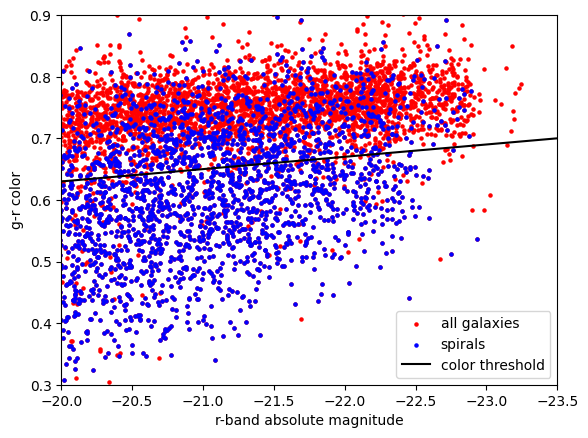

In [218]:
plt.scatter(all_galaxies["r"], all_galaxies["g-r"], s=5, color='red', label='all galaxies')
plt.scatter(spirals["r"], spirals["g-r"], s=5, color='blue', label='spirals')
plt.plot(M_r, g_r, color='black', label='color threshold')
plt.xlim(-20, -23.5)
plt.ylim(0.3, 0.9)
plt.xlabel("r-band absolute magnitude")
plt.ylabel("g-r color")
plt.legend()
#plt.title("")
plt.show()

Now, let's make the cutoff line for NUV-r, given in this paper: https://ui.adsabs.harvard.edu/abs/2022MNRAS.510.4126S/abstract. It is defined as

NUV - r = 4.961

So, we can translate this by simply adding NUV_r as a horizontal line at 4.961 using the "plt.axline" command.

So let's plot our r-band vs. NUV-r graph...

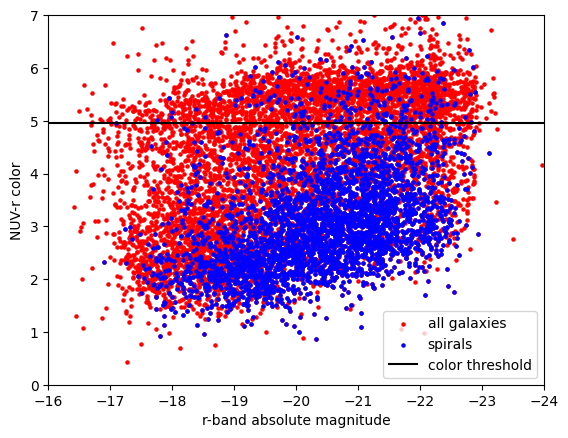

In [219]:
plt.scatter(all_galaxies["r"], all_galaxies["NUV-r"], s=5, color='red', label='all galaxies')
plt.scatter(spirals["r"], spirals["NUV-r"], s=5, color='blue', label='spirals')
plt.axhline(y=4.961, color='black', label='color threshold')
plt.xlim(-16, -24)
plt.ylim(0,7)
plt.xlabel("r-band absolute magnitude")
plt.ylabel("NUV-r color")
plt.legend()
#plt.title("")
plt.show()

Now that we have our plots, we can see some trends arising towards which samples (all galaxies or spirals) lean more red or more blue.

Let's include a summary of the numbers of red/blue galaxies from each sample using some statistical methods so we can know just how many galaxies are above or below the thresholds.

Doing this for our g-r plot is going to be a bit trickier as our threshold is not simply a horizontal line, but a complex equation. So, we can define this line as a function to run our sample through.

In [220]:
def g_r_threshold(M_r):
    return 0.63 - 0.02 * (M_r + 20)

Since anything above this line is considered "red," we can say that g-r values greater than (>) the value we get when we plug in any r value to the function are red. Likewise, anything less than or equal to (<=) this value is considered "blue."

Let's define galaxies as red or blue for both samples and see where they fall...

In [221]:
red_all_gr = (all_galaxies['g-r']>g_r_threshold(all_galaxies['r'])).sum()
blue_all_gr = (all_galaxies['g-r']<=g_r_threshold(all_galaxies['r'])).sum()
# defining all galaxies based on position relative to our threshold

Now let's do the same thing for the spirals and print all of the information out as one paragraph.

In [222]:
red_spi_gr = (spirals['g-r']>g_r_threshold(spirals['r'])).sum()
blue_spi_gr = (spirals['g-r']<=g_r_threshold(spirals['r'])).sum()
# defining conditioned galaxies based on position relative to our threshold

In [223]:
print("g-r classification")
print(f"All Galaxies: Red = {red_all_gr}, Blue = {blue_all_gr}")
print(f"Spirals: Red = {red_spi_gr}, Blue = {blue_spi_gr}")

g-r classification
All Galaxies: Red = 5709, Blue = 3913
Spirals: Red = 1124, Blue = 2311


We can also take it a step further and incorporate what percentage of the whole that is for each sample...

In [224]:
red_all_pct_gr = (red_all_gr)/(len(all_galaxies)) * 100
blue_all_pct_gr = (blue_all_gr)/(len(all_galaxies)) * 100

red_spi_pct_gr = (red_spi_gr)/(len(spirals)) * 100
blue_spi_pct_gr = (blue_spi_gr)/(len(spirals)) * 100

In [225]:
print("g-r Classification")
print(f"All Galaxies: Red = {red_all_gr} ({red_all_pct_gr:.1f}%), Blue = {blue_all_gr} ({blue_all_pct_gr:.1f}%)")
print(f"Spirals: Red = {red_spi_gr} ({red_spi_pct_gr:.1f}%), Blue = {blue_spi_gr} ({blue_spi_pct_gr:.1f}%)")

g-r Classification
All Galaxies: Red = 5709 (59.3%), Blue = 3913 (40.7%)
Spirals: Red = 1124 (32.7%), Blue = 2311 (67.3%)


For NUV-r, we're basically doing the same thing, but it's simpler since our threshold is just one value (4.961) instead of a function.

In [226]:
red_all_nr = (all_galaxies['NUV-r']>4.961).sum()
blue_all_nr = (all_galaxies['NUV-r']<=4.961).sum()

red_spi_nr = (spirals['NUV-r']>4.961).sum()
blue_spi_nr = (spirals['NUV-r']<=4.961).sum()

In [227]:
red_all_pct_nr = (red_all_nr)/(len(all_galaxies)) * 100
blue_all_pct_nr = (blue_all_nr)/(len(all_galaxies)) * 100

red_spi_pct_nr = (red_spi_nr)/(len(spirals)) * 100
blue_spi_pct_nr = (blue_spi_nr)/(len(spirals)) * 100

In [228]:
print("NUV-r Classification")
print(f"All Galaxies: Red = {red_all_nr} ({red_all_pct_nr:.1f}%), Blue = {blue_all_nr} ({blue_all_pct_nr:.1f}%)")
print(f"Spirals: Red = {red_spi_nr} ({red_spi_pct_nr:.1f}%), Blue = {blue_spi_nr} ({blue_spi_pct_nr:.1f}%)")

NUV-r Classification
All Galaxies: Red = 2677 (27.8%), Blue = 6945 (72.2%)
Spirals: Red = 226 (6.6%), Blue = 3209 (93.4%)


Before we interpret these results, let's check if the NUV-r red spirals are also red in the g-r selection.

In [229]:
all_galaxies['g-r class'] = np.where(all_galaxies['g-r']>g_r_threshold(all_galaxies['r']), 'red', 'blue')
# adds a class where if it's > the threshold then it's red, if not, blue

all_galaxies['NUV-r class'] = np.where(all_galaxies['NUV-r']>4.961, 'red', 'blue')

We can find this by seeing if the columns in the "NUV-r class" also match that of the "g-r class." 

In [230]:
nr_red_all = all_galaxies[all_galaxies['NUV-r class'] == 'red']

both_red_all = (nr_red_all['g-r class'] == 'red').sum()
total_nr_red_all = len(nr_red_all)
total_red_all_pct = (both_red_all)/(len(nr_red_all)) * 100 # using a pct for further clarification

print(f"{both_red_all} out of {total_nr_red_all} ({total_red_all_pct:.1f}%) NUV-r red spirals are also g-r red for all galaxies")

2629 out of 2677 (98.2%) NUV-r red spirals are also g-r red for all galaxies


Now, let's simply do the same thing but for the spirals sample!

In [231]:
spirals['g-r class'] = np.where(spirals['g-r']>g_r_threshold(spirals['r']), 'red', 'blue')
# adds a class where if it's > the threshold then it's red, if not, blue

spirals['NUV-r class'] = np.where(spirals['NUV-r']>4.961, 'red', 'blue')

In [232]:
nr_red_spi = spirals[spirals['NUV-r class'] == 'red']

both_red_spi = (nr_red_spi['g-r class'] == 'red').sum()
total_nr_red_spi = len(nr_red_spi)
total_red_spi_pct = (both_red_spi)/(len(nr_red_spi)) * 100 # using a pct for further clarification

print(f"{both_red_spi} out of {total_nr_red_spi} ({total_red_spi_pct:.1f}%) NUV-r red spirals are also g-r red for these spirals")

218 out of 226 (96.5%) NUV-r red spirals are also g-r red for these spirals


Now let's make a Venn diagram to show the overlap in the spirals where they are both NUV-r and g-r red.

In [233]:
!pip install matplotlib-venn # installing venn diagram function from matplotlib

The import in the previous cell wasn't working when I first tried it, but the command in the next cell worked. I'm not sure if we need only one or both of these commands, so we'll keep them for now.

In [234]:
import sys
!{sys.executable} -m pip install matplotlib-venn

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.1.1 -> 26.1.1
[notice] To update, run: /packages/python3.10.10/bin/python -m pip install --upgrade pip


Now we can define the parts of our Venn diagram...

In [235]:
gr_red = set(spirals[spirals["g-r class"] == "red"].index)
nuvr_red = set(spirals[spirals["NUV-r class"] == "red"].index)

# setting our g-r/NUV-r categories in our df as sets that can be utilized in our Venn diagram

only_gr = len(gr_red - nuvr_red) # taking only the g-r red spirals (where g-r = red and NUV-r does not)
only_nuvr = len(nuvr_red - gr_red) # taking only the NUV-r red spirals (where NUV-r = red and g-r does not)
both = len(gr_red & nuvr_red) # taking both of these amounts (where g-r and NUV-r both = red)

And then, let's plot this Venn diagram...

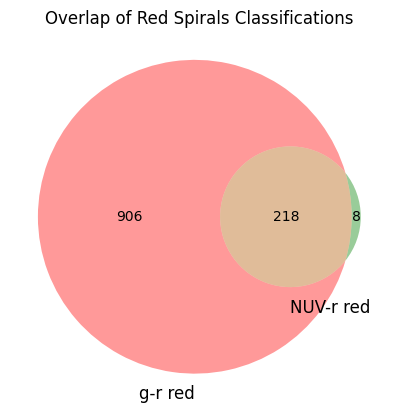

In [236]:
from matplotlib_venn import venn2 # importing our Venn 

venn2(subsets=(only_gr, only_nuvr, both), set_labels=('g-r red', 'NUV-r red'))

plt.title("Overlap of Red Spirals Classifications")
plt.show()

Now, we can interpret these results!

The red part of our Venn diagram represents red spirals that are only optically red (906 red spirals).

The yellow part of our Venn diagram represents NUV-r red spirals that are also g-r red (218 red spirals).

The small green part of the diagram represents NUV-r red spirals that are only UV red, not optically red (8 red spirals).

The green part (red spirals that are UV red but not optically red) are particularly interesting and worth looking into some more...

We can also make a plot that models the fraction of spirals that are red as our g-r threshold moves up equal increments. Essentially, the fraction should get smaller and smaller as the threshold line moves up.

In [237]:
def red_fraction(delta, df):
    threshold = 0.63 - 0.02*(df["r"] + 20) + delta
    
    red_spirals = (df["g-r"]>threshold).sum()
    
    return red_spirals/len(df)

# making a function that takes a df (we'll use the spirals df) and a delta that shifts the threshold up
# and returns the red spirals that are greater than the threshold vs. all of the red spirals

After this function, we'll create the inputs we'll use for the plot:

In [238]:
deltas = np.linspace(0,0.3,100) # going from adding 0 to 0.3 with steps of 100 for our x-variable

fractions = np.array([red_fraction(d, spirals) for d in deltas])
# using deltas as the change in our red_fraction function and spirals as the df

It should be noted that a change from 0 to 0.3 on our g-r plot really means that the y-intercept is increasing from about 0.63 to about 0.93. As one would predict, once the threshold gets that high, there's not many red spirals left on the plot.

Now, we can plot...

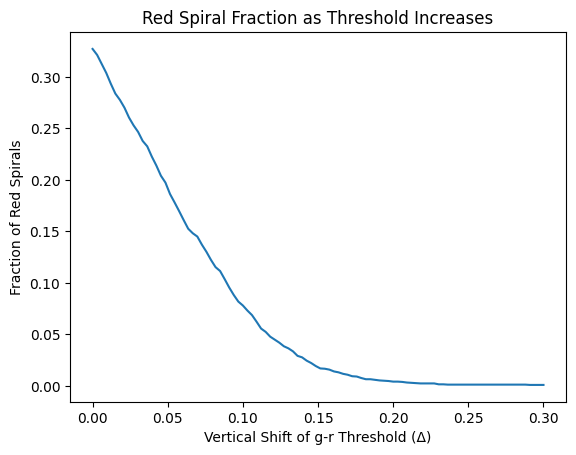

In [239]:
plt.plot(deltas, fractions)

plt.xlabel("Vertical Shift of g-r Threshold (Δ)")
plt.ylabel("Fraction of Red Spirals")
plt.title("Red Spiral Fraction as Threshold Increases")

plt.show()